# Robust sMOA with only 6, 8, or 11 observations

This notebook runs the labelled **smoke experiment** using the full original synthetic reference library. Hyperparameters are chosen from independently generated whole synthetic curves before the real histories are loaded. The target disease supplies no training errors or calibration outcomes.

M0 is original sMOA; M1 uses similarity-weighted medians; M2 regularizes original sMOA; M3 combines weighting and regularization. A synthetically selected beta of zero legitimately makes M2=M0 and M3=M1. This notebook does not force a positive regularization coefficient.

Prepare the existing local data described in the root README and install `requirements.txt`. The source and results of the previous ensemble implementation are archived outside the active pipeline.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / "configs/experiments.json").exists():
    ROOT = ROOT.parent
assert (ROOT / "configs/experiments.json").exists()
sys.path.insert(0, str(ROOT))
from experiments.robust.pipeline import load_config, run
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

config = load_config(ROOT / "configs/experiments.json")
RUN = run(config, experiment="all", smoke=True)
frozen = json.loads((RUN / "selected_config.json").read_text())
print("Smoke results:", RUN)
print("Frozen synthetic-only parameters:", {k: frozen[k] for k in ["temperature", "beta", "closest"]})
print("Validation source:", frozen["selected_on"])

/Users/nguyentranglinh/infectious-disease-forecasting/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Complete: /Users/nguyentranglinh/infectious-disease-forecasting/outputs/robust_smoa/smoke_72fa0178f355b11e


Smoke results: /Users/nguyentranglinh/infectious-disease-forecasting/outputs/robust_smoa/smoke_72fa0178f355b11e
Frozen synthetic-only parameters: {'temperature': 0.25, 'beta': 0.3, 'closest': 4422}
Validation source: independent_synthetic_curves_only


The forecasting API receives only a permitted history and frozen reference/parameters. `issued_predictions.csv.gz` is saved before future outcomes are attached. The observations shown below as dashed lines are final revised scoring values, not forecast inputs. This is an early-origin design: T counts the first observations since the recorded observed onset.

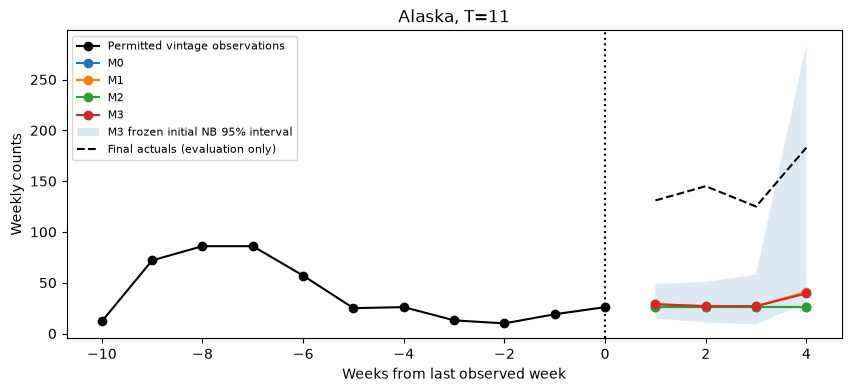

In [2]:
issued = pd.read_csv(RUN / "issued_predictions.csv.gz", dtype={"case_id": str})
assert "actual" not in issued
predictions = pd.read_csv(RUN / "predictions.csv.gz", dtype={"case_id": str})
real = predictions.loc[predictions.dataset.eq("COVID19_early")]
diagnostics = {row["case_id"]: row for row in json.loads((RUN / "matching_diagnostics.json").read_text())}
case_id = real.case_id.drop_duplicates().iloc[-1]
block = real.loc[real.case_id.eq(case_id)]
history = np.asarray(diagnostics[case_id]["history"])
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(1-len(history), 1), history, "ko-", label="Permitted vintage observations")
for model, group in block.groupby("model"):
    group = group.sort_values("horizon")
    ax.plot(group.horizon, group.prediction, "o-", label=model)
robust = block.loc[block.model.eq("M3")].sort_values("horizon")
ax.fill_between(robust.horizon, robust.q025, robust.q975, alpha=.15, label="M3 frozen initial NB 95% interval")
ax.plot(robust.horizon, robust.actual, "k--", label="Final actuals (evaluation only)")
ax.axvline(0, color="black", linestyle=":")
ax.set(title=f"{block.region.iloc[0]}, T={len(history)}", xlabel="Weeks from last observed week", ylabel="Weekly counts")
ax.legend(fontsize=8)
plt.show()

Kernel SHAP evaluates the actual forecasting function, including GAM, rematching, weighted median reconstruction and regularization, for every changed history. It explains both the M3 forecast count and M3−M0 at a fixed horizon. Background windows come from a separate synthetic role and are rescaled using the observed history mean only. All T supplied observations are explained.

Examples chosen using completed errors are retrospective interpretation, not tuning. Correlated weeks, background dependence, and implausible hybrid sequences limit interpretation; the values are not causal.

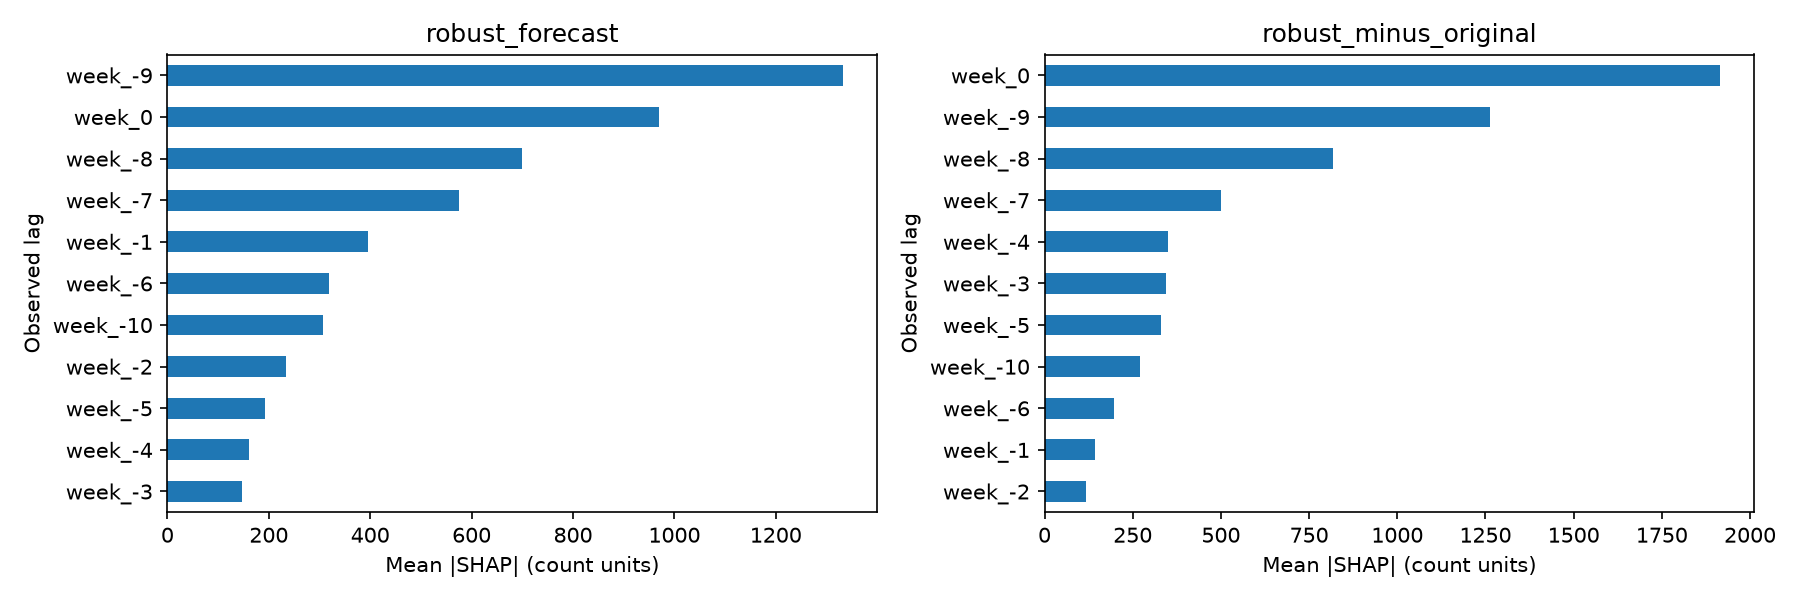

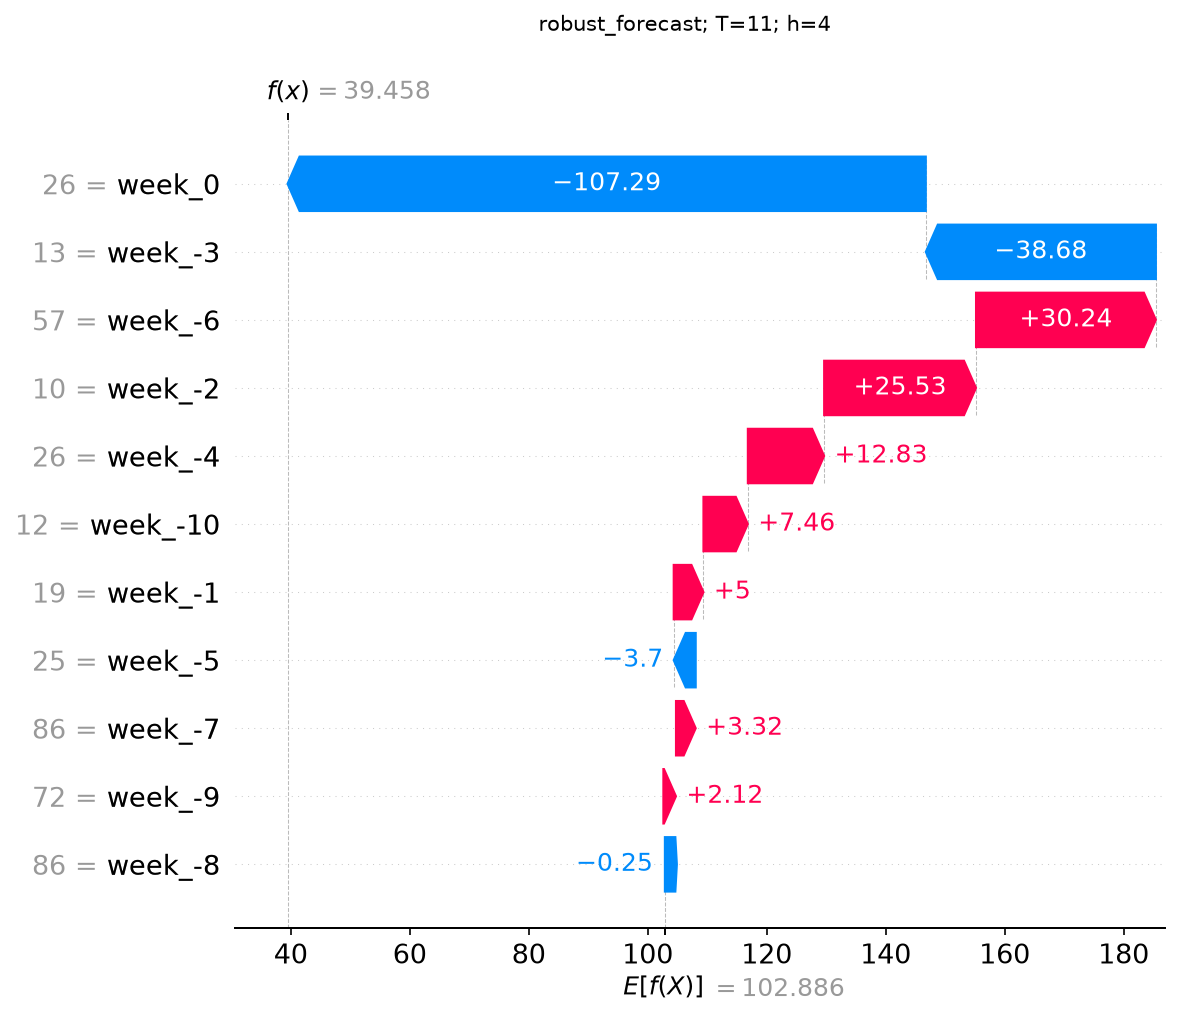

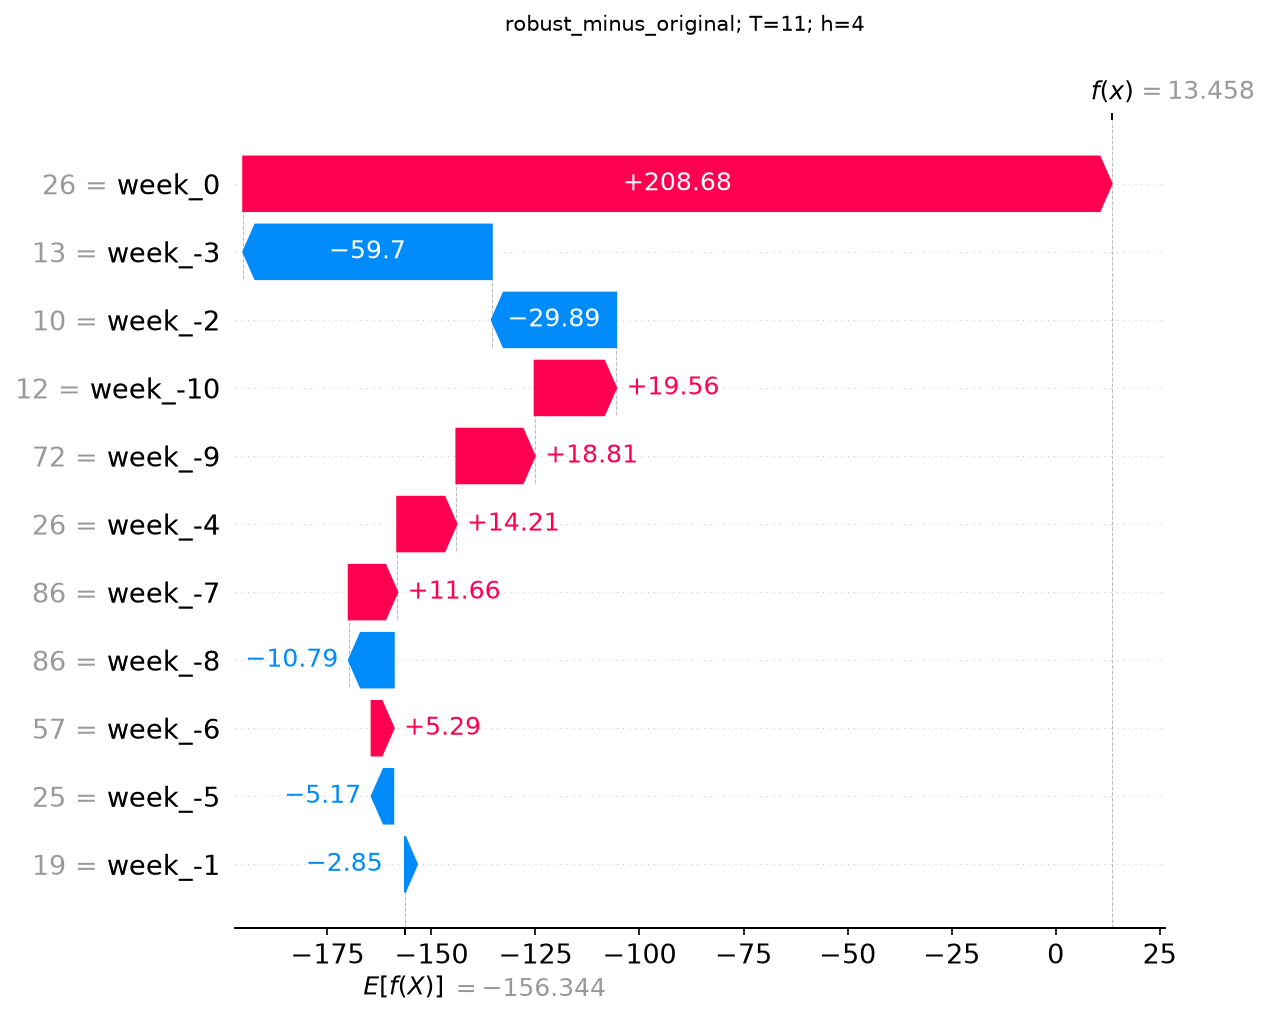

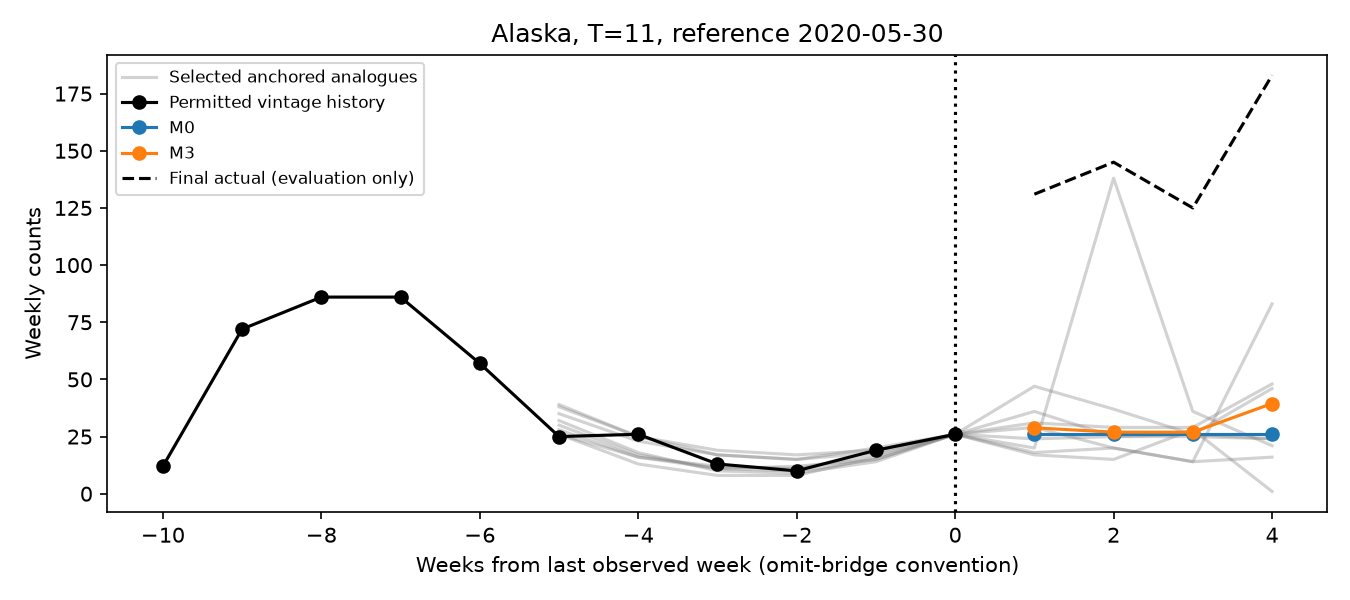

,case_id,target,mean_absolute_background_change,rank_correlation
0,5,robust_forecast,10.643068,0.363636
1,5,robust_minus_original,22.299593,0.618182
2,2,robust_forecast,1135.226475,-0.490909
3,2,robust_minus_original,991.724448,0.072727
4,0,robust_forecast,190.737018,0.885714
5,0,robust_minus_original,215.763841,1.000000
6,1,robust_forecast,142.605269,0.833333
7,1,robust_minus_original,217.594693,0.761905


In [3]:
display(Image(filename=str(RUN / "shap_summary.png")))
display(Image(filename=str(RUN / "shap_case_0_robust_forecast.png")))
display(Image(filename=str(RUN / "shap_case_0_robust_minus_original.png")))
display(Image(filename=str(RUN / "analogues_case_0.png")))
display(pd.read_csv(RUN / "explanation_stability.csv"))

In [4]:
metrics = pd.read_csv(RUN / "metrics.csv")
display(metrics[["dataset", "model", "n", "mae", "rmse", "bias", "relative_mae_improvement", "severe_underprediction"]])
display(pd.read_csv(RUN / "uncertainty_metrics.csv")[["dataset", "model", "wis", "coverage_95", "width_95"]])
print("These are smoke results, not the full study.")
print("Cold-start NB sizes are frozen: no target-disease residual calibration is used.")
print("Real COVID periods were explored previously; this is not independent cross-disease confirmation.")

,dataset,model,n,mae,rmse,bias,relative_mae_improvement,severe_underprediction
0,COVID19_early,M0,24,357.875000,5.952214e+02,-208.500000,0.000000,0.458333
1,COVID19_early,M1,24,473.416667,7.825612e+02,-394.166667,-0.322855,0.583333
2,COVID19_early,M2,24,382.775164,6.255887e+02,-282.862227,-0.069578,0.375000
3,COVID19_early,M3,24,487.108963,7.901065e+02,-411.762434,-0.361115,0.583333
4,synthetic_check,M0,108,375540.962963,9.392518e+05,-248907.953704,0.000000,0.277778
5,synthetic_check,M1,108,415033.120370,1.035312e+06,-292393.157407,-0.105161,0.351852
6,synthetic_check,M2,108,364655.733640,9.018772e+05,-230418.308580,0.028985,0.296296
7,synthetic_check,M3,108,385617.183173,9.502713e+05,-255585.894305,-0.026831,0.333333


,dataset,model,wis,coverage_95,width_95
0,COVID19_early,M0,273.052552,0.625000,3.553791e+03
1,COVID19_early,M1,304.235722,0.500000,2.799330e+03
2,COVID19_early,M2,257.811009,0.666667,3.178601e+03
3,COVID19_early,M3,287.793224,0.541667,2.730705e+03
4,synthetic_check,M0,245942.005648,0.574074,1.274134e+06
5,synthetic_check,M1,293236.877583,0.481481,1.139725e+06
6,synthetic_check,M2,241000.510238,0.527778,1.361267e+06
7,synthetic_check,M3,258735.540508,0.500000,1.270072e+06


These are smoke results, not the full study.
Cold-start NB sizes are frozen: no target-disease residual calibration is used.
Real COVID periods were explored previously; this is not independent cross-disease confirmation.
